<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/Day_104_Tokenization_Practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 104/365 — Tokenization on Real Text

Today we learn how raw text becomes input for an LLM.

Pipeline:

`Text → Tokens → Token IDs → Embeddings → Transformer`

We use the **UCI SMS Spam Collection** as a real text dataset and compare:

- word-level tokenization
- character-level tokenization
- subword BPE tokenization


In [9]:
# Install SentencePiece if needed
# !pip install sentencepiece pandas matplotlib

import io
import re
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sentencepiece as spm


## 1. Load the real UCI SMS Spam Collection

In [10]:
UCI_URL = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00228/"
    "smsspamcollection.zip"
)

fallback_rows = [
    ("ham", "Ok lar... Joking wif u oni..."),
    ("ham", "Nah I don't think he goes to usf, he lives around here though"),
    ("ham", "Even my brother is not like to speak with me."),
    ("ham", "I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k?"),
    ("ham", "I HAVE A DATE ON SUNDAY WITH WILL!!"),
    ("ham", "Sorry, I'll call later in meeting."),
    ("ham", "Tell where you reached"),
    ("ham", "Fair enough, anything going on?"),
    ("ham", "I'm home."),
    ("ham", "Are you there in room."),
    ("spam", "Free entry in 2 a wkly comp to win FA Cup final tkts. Text FA to 87121."),
    ("spam", "WINNER!! As a valued network customer you have been selected to receive a prize reward!"),
    ("spam", "URGENT! You have won a FREE membership in our Prize Jackpot! Txt CLAIM now."),
    ("spam", "Your free ringtone is waiting to be collected. Text MIX to verify."),
]

try:
    raw = urllib.request.urlopen(UCI_URL, timeout=15).read()

    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        with z.open("SMSSpamCollection") as f:
            df = pd.read_csv(
                f,
                sep="\\t",
                header=None,
                names=["label", "text"]
            )

    source = "Full UCI dataset"

except Exception:
    df = pd.DataFrame(
        fallback_rows,
        columns=["label", "text"]
    )
    source = "Offline fallback sample from UCI SMS Spam Collection"

print("Source:", source)
print("Rows:", len(df))
df.head()


Source: Full UCI dataset
Rows: 5574


/tmp/ipykernel_1631/824228546.py:29: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Word-level and character-level tokenization

A token is not necessarily a whole word.

We start with two simple tokenizers.


In [11]:
def word_tokenize(text):
    return re.findall(
        r"\b\w+\b|[^\w\s]",
        text.lower()
    )

example = df.iloc[0]["text"]

word_tokens = word_tokenize(example)
character_tokens = list(example)

print("Text:")
print(example)

print("\nWord tokens:")
print(word_tokens)

print("\nCharacter tokens:")
print(character_tokens[:40])


Text:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Word tokens:
['go', 'until', 'jurong', 'point', ',', 'crazy', '.', '.', 'available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', '.', '.', '.', 'cine', 'there', 'got', 'amore', 'wat', '.', '.', '.']

Character tokens:
['G', 'o', ' ', 'u', 'n', 't', 'i', 'l', ' ', 'j', 'u', 'r', 'o', 'n', 'g', ' ', 'p', 'o', 'i', 'n', 't', ',', ' ', 'c', 'r', 'a', 'z', 'y', '.', '.', ' ', 'A', 'v', 'a', 'i', 'l', 'a', 'b', 'l', 'e']


## 3. Train a subword BPE tokenizer

Modern LLM tokenizers usually use subword ideas.

Subwords help represent unseen words without requiring a huge vocabulary.


In [12]:
training_file = "sms_tokenizer_training.txt"

with open(training_file, "w", encoding="utf-8") as f:
    for text in df["text"].astype(str):
        f.write(text.replace("\n", " ") + "\n")

vocab_size = min(
    800,
    max(64, len(df) * 4)
)

spm.SentencePieceTrainer.train(
    input=training_file,
    model_prefix="sms_bpe",
    vocab_size=vocab_size,
    model_type="bpe",
    character_coverage=1.0,
    hard_vocab_limit=False,
    bos_id=-1,
    eos_id=-1,
    pad_id=-1,
    unk_id=0
)

tokenizer = spm.SentencePieceProcessor(
    model_file="sms_bpe.model"
)

print("Vocabulary size:", tokenizer.get_piece_size())


Vocabulary size: 800


## 4. Compare tokenizers on the same real SMS

In [13]:
example = df.iloc[min(10, len(df)-1)]["text"]

word_tokens = word_tokenize(example)
subword_tokens = tokenizer.encode(example, out_type=str)
character_tokens = list(example)

print("TEXT:")
print(example)

print("\nWord tokens:", len(word_tokens))
print(word_tokens)

print("\nSubword tokens:", len(subword_tokens))
print(subword_tokens)

print("\nCharacter tokens:", len(character_tokens))


TEXT:
I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today.

Word tokens: 30
['i', "'", 'm', 'gonna', 'be', 'home', 'soon', 'and', 'i', 'don', "'", 't', 'want', 'to', 'talk', 'about', 'this', 'stuff', 'anymore', 'tonight', ',', 'k', '?', 'i', "'", 've', 'cried', 'enough', 'today', '.']

Subword tokens: 40
['▁I', "'", 'm', '▁gon', 'na', '▁be', '▁home', '▁so', 'on', '▁and', '▁i', '▁don', "'", 't', '▁want', '▁to', '▁t', 'alk', '▁about', '▁this', '▁st', 'uff', '▁any', 'm', 'ore', '▁ton', 'ight', ',', '▁k', '?', '▁I', "'", 've', '▁c', 'ri', 'ed', '▁en', 'ough', '▁today', '.']

Character tokens: 109


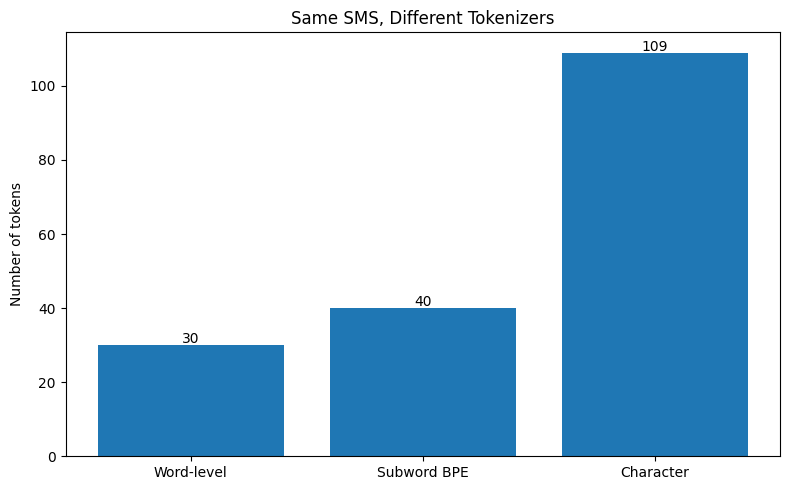

In [14]:
plt.figure(figsize=(8,5))

labels = [
    "Word-level",
    "Subword BPE",
    "Character"
]

counts = [
    len(word_tokens),
    len(subword_tokens),
    len(character_tokens)
]

plt.bar(labels, counts)

plt.ylabel("Number of tokens")
plt.title("Same SMS, Different Tokenizers")

for i, value in enumerate(counts):
    plt.text(i, value + 0.5, str(value), ha="center")

plt.tight_layout()
plt.show()


## 5. Out-of-vocabulary words

A word-level tokenizer may map unseen words to `<UNK>`.

A subword tokenizer can often split them into smaller reusable pieces.


In [15]:
training_vocab = set()

for text in df["text"].astype(str).iloc[:-1]:
    training_vocab.update(
        word_tokenize(text)
    )

unseen_text = "unbelievably urgent cashback offer"

word_result = [
    token if token in training_vocab else "<UNK>"
    for token in word_tokenize(unseen_text)
]

subword_result = tokenizer.encode(
    unseen_text,
    out_type=str
)

print("Input:")
print(unseen_text)

print("\nWord-level:")
print(word_result)

print("\nSubword:")
print(subword_result)


Input:
unbelievably urgent cashback offer

Word-level:
['<UNK>', 'urgent', '<UNK>', 'offer']

Subword:
['▁un', 'b', 'el', 'ie', 'v', 'ab', 'ly', '▁ur', 'g', 'ent', '▁cash', 'b', 'ack', '▁off', 'er']


## 6. Tokens become token IDs

The Transformer does not receive token strings.

Each token is converted to an integer ID.


In [16]:
text = df.iloc[0]["text"]

pieces = tokenizer.encode(
    text,
    out_type=str
)

token_ids = tokenizer.encode(
    text,
    out_type=int
)

print("Text:")
print(text)

print("\nTokens:")
print(pieces)

print("\nToken IDs:")
print(token_ids)


Text:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Tokens:
['▁G', 'o', '▁u', 'nt', 'il', '▁j', 'ur', 'ong', '▁p', 'oin', 't', ',', '▁c', 'ra', 'z', 'y', '..', '▁A', 'v', 'ail', 'able', '▁only', '▁in', '▁b', 'u', 'g', 'is', '▁n', '▁great', '▁wor', 'ld', '▁la', '▁e', '▁b', 'uff', 'et', '...', '▁C', 'ine', '▁there', '▁got', '▁am', 'ore', '▁wat', '...']

Token IDs:
[102, 687, 32, 162, 160, 123, 170, 335, 30, 571, 688, 713, 12, 262, 750, 700, 11, 62, 710, 526, 676, 279, 54, 19, 697, 702, 56, 27, 491, 181, 128, 286, 66, 19, 670, 40, 49, 61, 203, 247, 233, 235, 193, 340, 49]


## 7. Token IDs become embeddings

Conceptually:

`"urgent" → token ID 153`

Then an embedding table maps that ID to a dense vector:

`153 → [0.21, -0.44, 0.08, ...]`

That vector is what enters the Transformer.


## 8. Why tokenization matters in production

Tokenization affects:

- context-window usage
- inference cost
- latency
- prompt length
- truncation
- RAG chunking
- multilingual behavior

Two strings with the same number of characters may produce very different token counts.


## Simple takeaway

An LLM does not read text directly.

It sees:

`Text → Tokens → Token IDs → Embedding vectors`

> **Tokenization decides the basic units of language the model is allowed to see.**


## References

- UCI SMS Spam Collection:
  https://archive.ics.uci.edu/dataset/228/sms+spam+collection

- SentencePiece:
  https://github.com/google/sentencepiece

- SentencePiece paper:
  https://arxiv.org/abs/1808.06226

- Attention Is All You Need:
  https://arxiv.org/abs/1706.03762
